# A reaction yield: a sample made of several molecules

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/09_a_reaction_yield.ipynb)

In every earlier notebook a sample was one molecule, or one catalyst. A table of reactions is
different. Each row is a **combination** of molecules: a catalyst, a base, a reagent, and the
yield that this combination gave. Two rows share some of their molecules and differ in others.

This notebook uses the screen of Ahneman, Estrada, Lin, Dreher and Doyle (Science 360 (2018)
186). A palladium-catalysed coupling of 4-methylaniline was run with every combination of 15 aryl
halides, 4 ligands, 3 bases and 22 isoxazole additives, and 3,955 of the 3,960 reactions have a
yield. It is the standard benchmark of yield prediction, with published splits. The notebook asks
three questions.

1. How does one kernel describe a combination of molecules?
2. Does the frame of the reacting bond help here, as it did on the catalysts of the eighth
   notebook (+0.13)?
3. What does a **new** aryl halide need: a structure, or only the names of its parts?

The third question has a cheap reference that the first measurement of this set did not have,
and it changes what that measurement said. The notebook runs the fits itself and reads the long
benchmark (`benchmarks/run_buchwald.py`, about seven hours) from its stored results.

Running time: about three minutes.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The screen

`examples/buchwald/` holds the reactions (`reactions.csv`), the four kinds of component
(`components.csv`), the splits that every paper on this set uses (`splits.csv`), and the aryl
halides and additives as 3D structures in the frame of their reacting bond. The ligands and the
bases have no structure here. With four and three members a model can only tell them apart, and
their names already do that. `Reactions` in the benchmark script reads all of it.

3955 reactions, yield 33.1 % on average (standard deviation 27.3), 10 % of them below 1 %
ligand        4 members, the mean yield of a member runs from 20.2 to 41.1 %
base          3 members, the mean yield of a member runs from 27.0 to 41.5 %
aryl_halide  15 members, the mean yield of a member runs from  1.9 to 58.6 %
additive     22 members, the mean yield of a member runs from  9.0 to 46.7 %


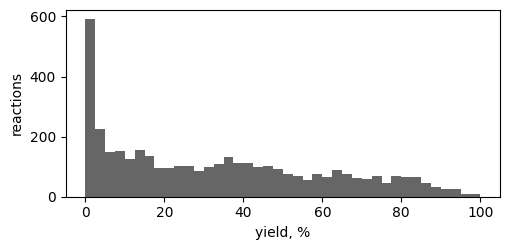

In [2]:
import json
import os
import sys

os.environ["CMF_KERNEL_CACHE"] = "0"
sys.path.insert(0, "benchmarks")

import matplotlib.pyplot as plt
import numpy as np

import run_buchwald as bw               # the data, kernels, folds and fits of the benchmark

data = bw.Reactions()
y = data.y
print("%d reactions, yield %.1f %% on average (standard deviation %.1f), %.0f %% of them below 1 %%" % (
    data.n, y.mean(), y.std(), 100 * (y < 1).mean()))
for role in bw.ROLES:
    means = [y[data.index[role] == i].mean() for i in range(len(data.labels[role]))]
    print("%-12s %2d members, the mean yield of a member runs from %4.1f to %4.1f %%" % (
        role, len(means), min(means), max(means)))

fig, ax = plt.subplots(figsize=(5.2, 2.6))
ax.hist(y, bins=40, color="0.4")
ax.set_xlabel("yield, %")
ax.set_ylabel("reactions")
plt.tight_layout()
plt.show()

The 15 aryl halides are not 15 unrelated molecules. They are every combination of 5 arenes and
3 halogens. The next table shows the mean yield of each, over the 264 reactions of that aryl
halide.

In [3]:
lab = data.labels["aryl_halide"]
arene = np.array([l.rsplit("-", 1)[0] for l in lab])
halogen = np.array([l.rsplit("-", 1)[1] for l in lab])
mean_yield = {l: y[data.index["aryl_halide"] == i].mean() for i, l in enumerate(lab)}
print("%-14s %8s %8s %8s" % ("arene", "Cl", "Br", "I"))
for a in data.arenes:
    print("%-14s " % a + " ".join("%6.1f %%" % mean_yield["%s-%s" % (a, h)] for h in ("Cl", "Br", "I")))

arene                Cl       Br        I
2-pyridyl        43.5 %   52.4 %   58.6 %
3-pyridyl        13.8 %   43.0 %   51.3 %
4-CF3-phenyl     12.5 %   26.9 %   33.7 %
4-Et-phenyl       3.9 %   43.5 %   52.6 %
4-MeO-phenyl      1.9 %   25.9 %   32.5 %


## One kernel for a combination

The kernel of two reactions is a **product over their components**,

    K(r, s) = product over the four components c of ( 1 + K_c(c_r, c_s) ),

where K_c is the kernel of that component: the identity kernel (1 for the same molecule, 0 for
another) when a component is known by its name, and a field kernel or a fingerprint kernel when
it has a structure. Expanded, the product has one term for every component and for every pair,
triple and quadruple of components. A kernel model on it can therefore fit a main effect of each
component and every interaction among them. This is called an **ANOVA kernel**. The fit is a kernel
ridge regression, as before.

The next cell builds the kernels of the two components that have a structure, in four
descriptions, and checks the product formula on one pair of reactions.

- **names**: the identity kernel, the description that sees no structure;
- **fingerprints**: the Tanimoto kernel of Morgan fingerprints;
- **fields, no frame**: the rotation-invariant kernel of the second notebook;
- **fields in the frame**: the overlap of the fields, each aryl halide in the frame of its C-X
  bond and each additive in the frame of its N-O bond (attenuation 5, cosine-normalised).

The last two have one setting each here. The benchmark chooses the setting inside every
training part; the values below are the ones it chose most often on the additive splits.

In [4]:
kernels = {}
for role in bw.BUILT:
    kernels[role] = {
        "names": np.eye(len(data.labels[role])),
        "fingerprints": bw.fingerprint_kernel(data, role),
        "fields, no frame": bw.invariant_kernel(data, role, 0.07),
        "fields in the frame": bw.frame_kernel(data, role, 5.0, True),
    }


def reaction_kernel(method, parts=False):
    # the ligand and the base always enter by name; the two built components in `method`
    comps = {r: np.eye(len(data.labels[r])) for r in bw.ROLES}
    for role in bw.BUILT:
        comps[role] = kernels[role][method]
    if parts:
        comps["aryl_halide"] = bw.parts_kernel(data, "parts_product")
    return bw.reaction_kernel(data, comps, "anova"), comps


K, comps = reaction_kernel("fingerprints")
# the formula on one pair of reactions that share ligand and base and differ in the other two
r = 0
s = int(np.where((data.index["ligand"] == data.index["ligand"][r]) & (data.index["base"] == data.index["base"][r])
                 & (data.index["aryl_halide"] != data.index["aryl_halide"][r])
                 & (data.index["additive"] != data.index["additive"][r]))[0][0])
by_hand = 1.0
for role in bw.ROLES:
    by_hand *= 1.0 + comps[role][data.index[role][r], data.index[role][s]]
print("kernel of reactions %s and %s: from the product %.4f, from the benchmark %.4f" % (
    data.ids[r], data.ids[s], by_hand, K[r, s]))
print("the reaction kernel is %d x %d and is built from four small matrices (%s)" % (
    K.shape[0], K.shape[1], ", ".join("%d x %d" % comps[role].shape for role in bw.ROLES)))

kernel of reactions R0001 and R0002: from the product 6.8449, from the benchmark 6.8449
the reaction kernel is 3955 x 3955 and is built from four small matrices (4 x 4, 3 x 3, 15 x 15, 22 x 22)


### Three descriptions of the additives as whole kernels

An isoxazole additive is described by 22 x 22 numbers in each description. The correlation of
the off-diagonal entries of two such kernels says how much the two descriptions agree, before
any model is fitted. A correlation near 1 means that the second description can add little to
the first. A low correlation means that the descriptions differ. It does not say which one is
right.

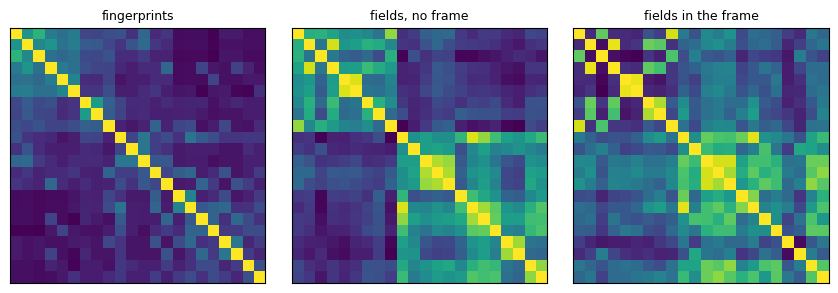

aryl halide kernels, correlation of the off-diagonal entries:
   fingerprints         with fields, no frame     +0.83
   fingerprints         with fields in the frame  +0.64
   fields, no frame     with fields in the frame  +0.66
additive kernels, correlation of the off-diagonal entries:
   fingerprints         with fields, no frame     +0.62
   fingerprints         with fields in the frame  +0.27
   fields, no frame     with fields in the frame  +0.61


In [5]:
def correlation(A, B):
    upper = np.triu_indices(A.shape[0], 1)
    return float(np.corrcoef(A[upper], B[upper])[0, 1])


shown = ["fingerprints", "fields, no frame", "fields in the frame"]
fig, axes = plt.subplots(1, 3, figsize=(8.6, 2.9))
for ax, name in zip(axes, shown):
    ax.imshow(kernels["additive"][name], cmap="viridis")
    ax.set_title(name, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()
for role in bw.BUILT:
    print("%s kernels, correlation of the off-diagonal entries:" % role.replace("_", " "))
    for i in range(3):
        for j in range(i + 1, 3):
            print("   %-20s with %-20s %+.2f" % (shown[i], shown[j], correlation(kernels[role][shown[i]], kernels[role][shown[j]])))

The descriptions agree most on the aryl halides, where the correlations run from 0.64 to 0.83. They
agree least on the additives, where the kernel of the fields in the frame is the least like the
fingerprints (0.27). This says that the frame reads something different from the fingerprints. It
does not say that what it reads is useful, and the fits below test that.

## The aryl halides are a grid: what their parts already say

Because the 15 aryl halides are every combination of 5 arenes and 3 halogens, a held-out aryl
halide is not a stranger. Its arene is in the training part with the other two halogens, and its
halogen is there with the other four arenes. A description that says only **which arene and which
halogen** already knows something about it. This is the cheap reference of this notebook. It is
the identity kernel of the arene plus the identity kernel of the halogen, and it reads no
structure. A second form adds the product of the two, which is the name of the whole aryl halide.
`parts_kernel` in the benchmark builds both.

A linear model on the first form is a Free-Wilson model: each arene and each halogen gets an
effect, and no pair of them gets an effect of its own. The yields have such pair effects. The
cell below regresses the 15 mean yields on the arene and the halogen, and then looks at the
linear frame kernel of the fields. A field is a sum of atom Gaussians, so in a shared frame the
field of an aryl halide is close to the field of its arene plus that of its halogen. The kernel
then has about 5 + 3 - 1 = 7 independent directions, which is the rank of the Free-Wilson model.

In [6]:
mean = np.array([mean_yield[l] for l in lab])
X = np.hstack([(arene[:, None] == np.array(data.arenes)).astype(float),
               (halogen[:, None] == np.array(["Br", "Cl", "I"])).astype(float)])
beta = np.linalg.lstsq(X, mean, rcond=None)[0]
residual = mean - X @ beta
share = 1.0 - (residual ** 2).sum() / ((mean - mean.mean()) ** 2).sum()
print("a linear regression on the arene and the halogen explains %.1f %% of the variance of the 15 mean yields" % (100 * share))
for l, r in sorted(zip(lab, residual), key=lambda t: t[1])[:2]:
    print("   the mean yield of %s is %.1f points below the regression" % (l, -r))

check = bw.free_wilson_check(data)["aryl_halide"]
print("linear frame kernel of the aryl halides: %d of %d eigenvalues above 1e-3 of the largest, %.4f %% of it in the span of an arene part plus a halogen part (rank %d)" % (
    check["above_1e-3"], check["n"], 100 * check["share_in_arene_plus_halogen"], check["rank_arene_plus_halogen"]))
print("rank of the parts kernel, the two names added: %d; with their product: %d" % (
    np.linalg.matrix_rank(bw.parts_kernel(data, "parts_sum")), np.linalg.matrix_rank(bw.parts_kernel(data, "parts_product"))))

a linear regression on the arene and the halogen explains 90.9 % of the variance of the 15 mean yields
   the mean yield of 4-Et-phenyl-Cl is 11.5 points below the regression
   the mean yield of 2-pyridyl-I is 5.6 points below the regression
linear frame kernel of the aryl halides: 7 of 15 eigenvalues above 1e-3 of the largest, 99.9991 % of it in the span of an arene part plus a halogen part (rank 7)
rank of the parts kernel, the two names added: 7; with their product: 15


## Four fits, run here

The benchmark chooses every setting and the ridge inside the training part, by a three-fold
cross-validation of the same kind as the split. `fit_design` below does the same for a kernel
with one setting: it chooses the ridge inside the training part by whole groups (whole additives
when the outer split holds out additives, whole arenes when it holds out arenes), then scores
the held-out part with R², the coefficient of determination. It uses the benchmark's own
functions `inner_folds` and `ridge_path`.

In [7]:
def fit_design(K, folds, group):
    pooled = np.full(data.n, np.nan)
    per_fold = []
    for fi, (name, mask) in enumerate(folds):
        train, test = np.where(~mask)[0], np.where(mask)[0]
        error = np.zeros(len(bw.LAMS))
        for pos in bw.inner_folds(data, train, group, bw.SEED + fi):
            keep = np.setdiff1d(np.arange(len(train)), pos)
            a, b = train[keep], train[pos]
            predicted = bw.ridge_path(K[np.ix_(a, a)], y[a], K[np.ix_(b, a)], bw.LAMS)
            error += ((predicted - y[b]) ** 2).sum(axis=1)
        best = int(np.argmin(error))
        pooled[test] = bw.ridge_path(K[np.ix_(train, train)], y[train], K[np.ix_(test, train)], [bw.LAMS[best]])[0]
        per_fold.append(bw.r2_score(y[test], pooled[test]))
    return pooled, per_fold

## A new additive: the frame costs

The published tests hold out five of the 22 additives at a time, four times. Here are four
descriptions on those tests. The names and the fingerprints have no setting. The two field
descriptions have the one setting given above, so their numbers differ a little from the
benchmark, which chose a setting in each training part.

In [8]:
tests = [(k, m) for k, m in data.published.items() if k.startswith("additive_test")]
methods = ["names", "fingerprints", "fields, no frame", "fields in the frame"]
stored = json.load(open(os.path.join(bw.OUT_DIR, "summary.json")))["methods"]
stored_key = {"names": "onehot", "fingerprints": "fingerprint", "fields, no frame": "invariant", "fields in the frame": "frame"}
live_tests = {}
print("%-22s %7s %7s %7s %7s   %7s   %s" % ("additive tests 1-4, R2", "test 1", "test 2", "test 3", "test 4", "mean", "stored mean"))
for m in methods:
    Km, _ = reaction_kernel(m)
    _, per = fit_design(Km, tests, "additive")
    live_tests[m] = per
    print("%-22s " % m + " ".join("%+7.3f" % r for r in per) + "   %+7.3f   %+7.3f" % (np.mean(per), stored[stored_key[m]]["additive tests"]["r2"]))

additive tests 1-4, R2  test 1  test 2  test 3  test 4      mean   stored mean


names                   +0.733  +0.737  +0.639  +0.623    +0.683    +0.683


fingerprints            +0.841  +0.822  +0.701  +0.544    +0.727    +0.727


fields, no frame        +0.798  +0.709  +0.681  +0.484    +0.668    +0.670


fields in the frame     +0.668  +0.608  +0.588  +0.415    +0.570    +0.537


In [9]:
stored_differences = json.load(open(os.path.join(bw.OUT_DIR, "summary.json")))["differences"]
print("stored benchmark, fields in the frame minus fields with no frame (R2):")
for key, label in (("additive tests: frame - invariant", "additive tests (mean of 4, range)"),
                   ("one additive out: frame - invariant", "each additive out (bootstrap interval)"),
                   ("one aryl halide out: frame - invariant", "each aryl halide out (bootstrap interval)")):
    d = stored_differences[key]
    print("   %-42s %+.3f  [%+.3f, %+.3f]" % (label, d["diff"], d["low"], d["high"]))

stored benchmark, fields in the frame minus fields with no frame (R2):
   additive tests (mean of 4, range)          -0.133  [-0.208, -0.093]
   each additive out (bootstrap interval)     -0.112  [-0.184, -0.029]
   each aryl halide out (bootstrap interval)  -0.004  [-0.076, +0.063]


The names reach 0.683 and the fingerprints 0.727. The fields with no frame reach 0.668, which is level
with the names. The fields in the frame are the lowest, at 0.570 here and 0.537 in the benchmark,
which chose the setting inside each training part. The stored differences show that the frame
costs on new additives: -0.133 on the four tests, and -0.112 [-0.184, -0.029] when each of the 22
additives is held out alone. On new aryl halides it costs nothing (-0.004 [-0.076, +0.063]).

The frame gave +0.13 on the catalysts of the eighth notebook. So that gain belongs to that series
and not to frames in general. A likely reason is that the isoxazoles differ in small groups at a
few positions. Put on top of each other at their N-O bond, their fields differ in few places, and
17 to 21 training additives are too few to say which places matter. This is a reading and not a
test. The fingerprints are the best description of the additives, and on the four published
tests they reach the published Yield-BERT (0.727 against 0.73).

## A new arene: the one test where a structure can matter

Holding out one aryl halide cannot tell a structure from the names of its parts, because the
parts are in the training part. A harder design holds out **all three halides of one arene
together**: five folds, with about 790 reactions in each. The arene is then new. Its name tells a
model nothing, and the names of the parts reduce to the name of the halogen. Only a description
of the arene itself can help. This design is new in this notebook, and `benchmarks/run_buchwald.py
--parts` runs it for every method of the benchmark.

The next cell runs five descriptions on it. Folds are chosen inside the training part by whole
arenes, so no arene is split.

In [10]:
arene_folds = bw.arene_designs(data)["one arene out"]
live_arene = {}
pooled_arene = {}
for m, parts in (("names", False), ("names of the parts", True), ("fingerprints", False),
                 ("fields, no frame", False), ("fields in the frame", False)):
    Km, _ = reaction_kernel("names" if parts else m, parts=parts)
    pooled_arene[m], live_arene[m] = fit_design(Km, arene_folds, "arene")
print("%-22s %9s   %s" % ("each arene out", "pooled R2", "R2 inside each arene: " + ", ".join(data.arenes)))
for m in pooled_arene:
    print("%-22s %+9.3f   " % (m, bw.r2_score(y, pooled_arene[m])) + "  ".join("%+7.3f" % r for r in live_arene[m]))

print()
print("difference in R2 against the names of the parts, bootstrap over the 5 held-out arenes:")
for m in ("fingerprints", "fields, no frame", "fields in the frame"):
    d = bw.bootstrap_difference(data, "arene", pooled_arene[m], pooled_arene["names of the parts"])
    print("   %-22s %+.3f  [%+.3f, %+.3f]" % (m, d["diff"], d["low"], d["high"]))

each arene out         pooled R2   R2 inside each arene: 2-pyridyl, 3-pyridyl, 4-CF3-phenyl, 4-Et-phenyl, 4-MeO-phenyl
names                     +0.198    -0.152   +0.325   -0.332   +0.262   -0.434
names of the parts        +0.441    -0.228   +0.629   +0.132   +0.689   +0.112
fingerprints              +0.491    +0.031   +0.563   +0.124   +0.684   +0.247
fields, no frame          +0.476    +0.053   +0.561   -0.089   +0.721   +0.124
fields in the frame       +0.379    +0.059   +0.613   -0.463   +0.549   -0.322

difference in R2 against the names of the parts, bootstrap over the 5 held-out arenes:
   fingerprints           +0.050  [-0.039, +0.161]
   fields, no frame       +0.035  [-0.077, +0.151]
   fields in the frame    -0.062  [-0.333, +0.103]


The names alone give 0.198, because a new arene cannot be told from the others. The names of the
parts give 0.441. For a new arene they reduce to the name of the halogen, and the effect of the
halogen is learned from the other four arenes. The three descriptions with a structure are within
0.06 of that: fingerprints +0.050, fields with no frame +0.035, and fields in the frame -0.062. Every
interval contains zero. Inside single arenes the order changes from one arene to the next, and the
frame is far below the parts for 4-CF3-phenyl (-0.463 against +0.132) and 4-MeO-phenyl (-0.322
against +0.112).

So even when the arene is new, this screen does not show that a structure adds to the name of the
halogen. This is not a proof that structure is useless. Five arenes, two of them pyridyls, are too
few to see a gain of 0.05, and a bootstrap over five groups is coarse.

The benchmark gives other numbers for the same design: 0.409 for the fields with no frame and
-0.201 for the fields in the frame. The reason is the setting. Here one setting is fixed for each
description, taken from the additive designs and not from this one. The benchmark chooses a setting
inside the four training arenes, among six or more. Which of the two ways reads better is not
tested here.

## All designs, from the stored run

The table below reads the stored results of the benchmark: every method, with every setting and
ridge chosen inside the training part, on the four designs of the benchmark and on the design
with each arene out. The rows with the names of the parts, and the column with each arene out,
come from `benchmarks/run_buchwald.py --parts`. The published values are from Table 1 of
Schwaller et al., Mach. Learn.: Sci. Technol. 2 (2021) 015016, on the same splits.

In [11]:
summary = json.load(open(os.path.join(bw.OUT_DIR, "summary.json")))
parts = json.load(open(os.path.join(bw.OUT_DIR, "parts.json")))
ms = summary["methods"]
header = "%-58s %7s %7s %7s %7s %7s"
print(header % ("R2, settings chosen inside the training part", "random", "add.tests", "add.out", "halide", "arene"))
print(header % ("", "70/30", "1-4", "each", "each", "each"))
for key in bw.ORDER:
    e = ms[key]
    print("%-58s %+7.3f %+7.3f %+7.3f %+7.3f %+7.3f" % (e["label"], e["random"]["r2"], e["additive tests"]["r2"],
          e["one additive out"]["r2"], e["one aryl halide out"]["r2"], parts["new"][key]["r2"]))
for key in bw.PARTS:
    print("%-58s %7s %7s %7s %+7.3f %+7.3f" % (parts["labels"][key], "", "", "", parts["halide"][key]["r2"], parts["new"][key]["r2"]))
for name, v in bw.PUBLISHED.items():
    print("%-58s %7.3f %7.2f" % ("published: " + name, v[0], np.mean(v[1:])))

R2, settings chosen inside the training part                random add.tests add.out  halide   arene
                                                             70/30     1-4    each    each    each
one-hot, main effects                                       +0.700  +0.589  +0.535  +0.194  +0.160
one-hot, all interactions                                   +0.909  +0.683  +0.626  +0.243  +0.198
Morgan fingerprints                                         +0.937  +0.727  +0.713  +0.696  +0.491
RDKit descriptors                                           +0.909  +0.612  +0.570  +0.720  +0.309
fields, no frame                                            +0.909  +0.670  +0.657  +0.724  +0.409
fields in the frame                                         +0.841  +0.537  +0.545  +0.720  -0.201
fields, no frame, Gaussian layer                            +0.910  +0.631  +0.629  +0.709  +0.442
fields in the frame, Gaussian layer                         +0.917  +0.545  +0.579  +0.659  +0.485
aryl hal

Four readings of the table.

1. **On a new additive**, fingerprints are the best of the descriptions (0.727 and 0.713). Fields
   with no frame are level with the names, and fields in the frame are below them.
2. **On a new aryl halide**, the names of the parts (0.700 and 0.708) are level with every
   description that has a structure (0.659 to 0.724). The name of the whole aryl halide gives
   0.243. In the benchmark every difference from the names of the parts has an interval that
   contains zero.
3. **On a new arene**, no description is clearly above the names of the parts (0.446 and 0.441).
   The linear frame model is lowest (-0.201), and the Gaussian layer repairs it (0.485), as it
   lifted the Free-Wilson limit on the random split (+0.076, stored).
4. **On the random 70/30 split** the descriptions that can express interactions are close (0.909
   to 0.937, and 0.841 for the linear frame), because every aryl halide and every additive is in
   the training part. Names with all interactions already reach 0.909, against 0.700 for main
   effects only. So the interaction terms hold most of what a random split can show, and a
   random split cannot tell the descriptions apart.

## What this shows and what it does not

**What it shows.**

- A sample can be a combination of molecules. The product kernel holds a main effect for each
  component and every interaction, and each component takes the description that suits it: a name, a
  fingerprint, or fields in a frame.
- Whether a frame helps is a property of the series and not of the method. It gained +0.13 on 43
  catalysts and lost 0.13 on new additives.
- A linear field model of a grid of parts is a Free-Wilson model. The 15 aryl halides have rank 7
  in the linear frame kernel, and one eigenvalue computation shows it. The Gaussian layer lifts the
  limit where the pairs are in the training part, and does not where a pair is held out.
- The reference for a new member of a grid is the names of its parts. On a new aryl halide it is
  level with every structure (0.70 against 0.66 to 0.72). The first measurement of this set read
  the 0.24 of the names alone against the 0.70 of the structures as "a new aryl halide needs a
  structure". The names of the parts show that it needs those names.

**What it does not show.**

- That a structure is useless for a new arene. Five arenes cannot resolve a difference of 0.05.
- Anything about the amine, which this screen does not vary, or about reaction tables that are
  not a grid of parts. It is one reaction with one amine.
- That a frame with a setting cannot work. The setting search inside 17 training additives is
  noisy: on additive test 1 the best of the 20 combinations of the frame with a Gaussian layer reaches
  0.825 when the ridge is chosen on the test part, and the search inside the training part chose
  one that reaches at most 0.718 (see the README).

The next step for a table of reactions is a second set in which a position varies and the
components are not a grid of parts, so that the names of the parts cannot be the reference.